In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
from pathlib import Path


In [2]:
df = pd.read_csv("../data/hotel_bookings.csv")
pd.set_option("display.max_columns", None)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.shape

(119390, 32)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
info = pd.DataFrame({
    'dtype': df.dtypes,
    'non_null': df.notnull().sum(),
    'null': df.isnull().sum(),
    'null_%': (df.isnull().mean() * 100).round(2),
    'unique': df.nunique()
})
info
# Tüm kolonların genel analizi

,dtype,non_null,null,null_%,unique
hotel,str,119390,0,0.00,2
is_canceled,int64,119390,0,0.00,2
lead_time,int64,119390,0,0.00,479
arrival_date_year,int64,119390,0,0.00,3
arrival_date_month,str,119390,0,0.00,12
arrival_date_week_number,int64,119390,0,0.00,53
arrival_date_day_of_month,int64,119390,0,0.00,31
stays_in_weekend_nights,int64,119390,0,0.00,17
stays_in_week_nights,int64,119390,0,0.00,35
adults,int64,119390,0,0.00,14


Duplicate Analysis

In [6]:
df.duplicated().sum()

np.int64(31994)

In [7]:
df[df.duplicated(keep=False)].head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.0,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.0,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08


In [8]:
# aynı seyahat acentesi, aynı tarihte aynı otelde konaklayacak iki farklı 
# müşteri için aynı özelliklerde rezervasyon yapmış olabilir.
#Tekrarlanan satırlar iptal edilen rezervasyonlarda mı, yoksa iptal edilmeyen rezervasyonlarda mı daha yoğun?

duplicates = df[df.duplicated(keep=False)]

duplicates.value_counts('is_canceled')


is_canceled
1    23451
0    16714
Name: count, dtype: int64

In [9]:
# Veri setindeki tüm rezervasyonların yüzde kaçı iptal edilmiş?

pct = (df.value_counts('is_canceled'))/(len(df)) *100
print(pct)

is_canceled
0    62.958372
1    37.041628
Name: count, dtype: float64


In [10]:
drop_duplicated = df.drop_duplicates()

drop_pct = (drop_duplicated.value_counts("is_canceled")/len(drop_duplicated)) * 100
print(drop_pct)

is_canceled
0    72.510184
1    27.489816
Name: count, dtype: float64


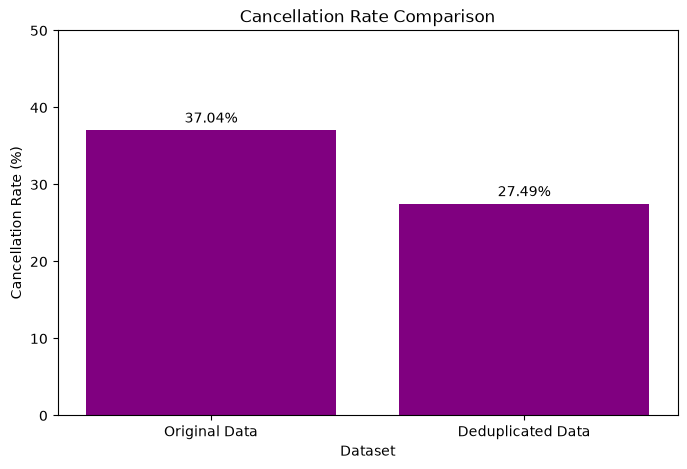

In [11]:
compare_df = pd.DataFrame({
    'dataset': ['Original Data', 'Deduplicated Data'],
    'cancel_rate': [37.04, 27.49]
})

plt.figure(figsize=(8,5))
plt.bar(compare_df['dataset'], compare_df['cancel_rate'], color = "purple")
plt.title('Cancellation Rate Comparison')
plt.xlabel('Dataset')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 50)

for i, v in enumerate(compare_df['cancel_rate']):
    plt.text(i, v + 1, f'{v:.2f}%', ha='center')

plt.show()

### Duplicate Analysis (Tekrarlanan Kayıt Analizi)

Veri setindeki tekrar eden kayıtlar `duplicated()` yöntemiyle incelenmiştir.

**1. Duplicate Kontrolü**

- Toplam kayıt sayısı: **119.390**
- Tekrar eden kayıt sayısı: **31.994 (%26,80)**
- Tekrarsızlaştırılmış kayıt sayısı: **87.396**

`duplicated(keep=False)` kullanılarak ilk kayıtlar dahil tüm eşleşen satırlar incelenmiştir. Örneklerde varış tarihleri, konaklama süreleri, kişi sayıları, fiyatlar ve diğer rezervasyon özelliklerinin birebir aynı olduğu gözlemlenmiştir.

Ancak veri setinde benzersiz bir rezervasyon veya müşteri kimliği bulunmadığından, bu eşleşmelerin kesin olarak hatalı kayıtlar olduğu söylenemez.

**2. Duplicate Kayıtların İptal Durumuna Göre İncelenmesi**

Tekrar eden gruplarda toplam **40.165 kayıt** bulunmaktadır.

- İptal edilen: 23.451 (%58,39)
- İptal edilmeyen: 16.714 (%41,61)

Ayrıca iptal edilen tüm rezervasyonların yaklaşık **%53'ü**, birebir aynı özelliklere sahip başka kayıtların bulunduğu gruplarda yer almaktadır.

Bu durum, tekrar eden kayıtlarla iptal durumu arasında bir ilişki olabileceğini göstermektedir. Ancak bu ilişki, tekrarların neden oluştuğunu açıklamak için tek başına yeterli değildir.

**3. Duplicate Temizliğinin İptal Oranına Etkisi**

`drop_duplicates()` yöntemiyle oluşturulan geçici bir veri seti üzerinde iptal oranları yeniden hesaplanmıştır.

| Metrik | Orijinal Veri | Tekrarsızlaştırılmış Veri |
|---|---:|---:|
| Toplam kayıt | 119.390 | 87.396 |
| İptal oranı | %37,04 | %27,49 |

Duplicate satırların çıkarılmasıyla iptal oranı **9,55 yüzde puan azalmıştır.**

Bu farklılık, tekrar eden kayıtların kaldırılmasının temel performans göstergelerini (KPI) önemli ölçüde değiştirebildiğini göstermektedir.

**4. Değerlendirme ve Karar**

Tekrarlanan kayıtların önemli bir kısmı iptal edilmiş rezervasyonlardan oluşmaktadır. Bunun nedenleri arasında rezervasyonların sistemde birden fazla kez kaydedilmesi veya aynı özelliklere sahip farklı rezervasyonların bulunması gibi ihtimaller değerlendirilebilir.

Ancak bu hipotezler mevcut verilerle doğrulanamamıştır.

**Veri temizleme kararı:** Orijinal veri seti korunacaktır. Tekrarsızlaştırılmış veri seti karşılaştırma amacıyla kullanılacak, duplicate kayıtların kalıcı olarak kaldırılmasına henüz karar verilmeyecektir.

Olasılık A — Sistemsel tekrar
Aslında tek bir rezervasyon yapılmıştır ancak sistem aynı rezervasyonu yanlışlıkla iki kez kaydetmiştir.
Bu durumda gerçekten fazladan bir kayıt vardır ve temizlenmesi gerekebilir.
Olasılık B — İki farklı rezervasyon
İki farklı müşteri aynı otelde, aynı tarihlerde ve aynı koşullarda rezervasyon yapmış, ardından ikisi de rezervasyonunu iptal etmiş olabilir.

Missing Values Analysis

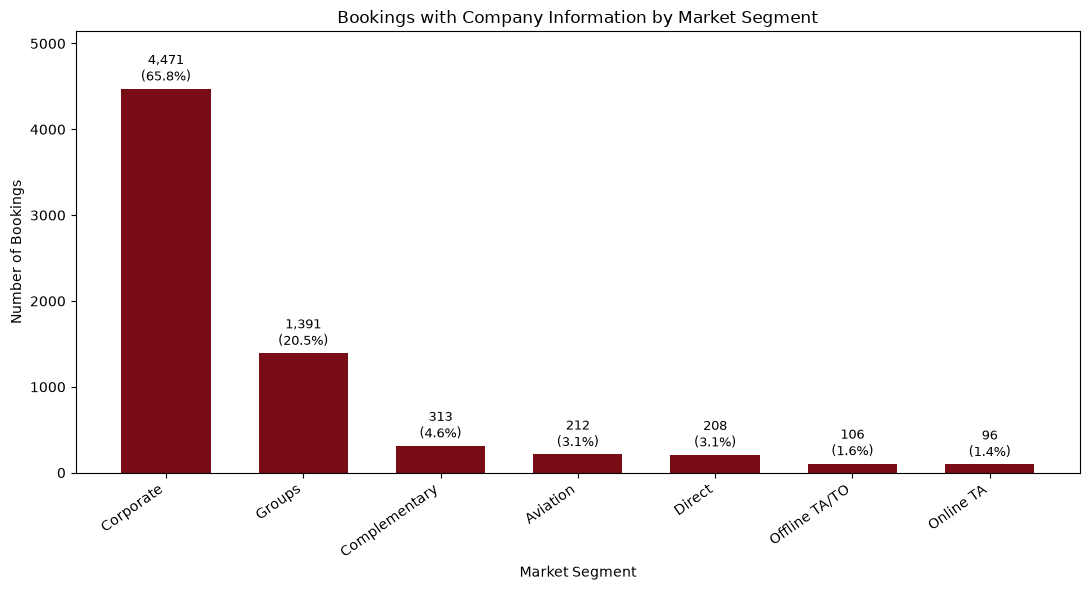

In [12]:
company_segment = df[df["company"].notna()]["market_segment"].value_counts()
company_pct = (company_segment / company_segment.sum()) * 100


plt.figure(figsize=(11, 6))

bars = plt.bar(
    company_segment.index,
    company_segment.values,
    color="#790D16",
    width=0.65
)

plt.title("Bookings with Company Information by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=35, ha="right")

# Sütunların üzerine değerleri ve yüzdeleri yazdır

labels = [
    f"{count:,}\n({pct:.1f}%)"
    for count, pct in zip(company_segment.values, company_pct.values)
]

plt.bar_label(bars, labels=labels, padding=3, fontsize=9)

plt.ylim(0, company_segment.max() * 1.15)
plt.tight_layout()
plt.show()

In [13]:
# yalnızca eksik değeri olan kolonlar
missing_value_summary = pd.DataFrame({
    "Missing Count" : df.isnull().sum(),
    "Missing Percentage" : ((df.isnull().mean())*100).round(4)
}) 
missing_value_summary[missing_value_summary["Missing Count"] >0].sort_values(by="Missing Percentage", ascending=False)

,Missing Count,Missing Percentage
company,112593,94.3069
agent,16340,13.6862
country,488,0.4087
children,4,0.0034


In [14]:
#Company bilgisi dolu olan rezervasyonlar hangi market segmentlerinde yoğunlaşıyor?
Count = df[df["company"].notna()].value_counts("market_segment") # her segmentteki company bilgisi dolu olan kayıt sayısı 
segmeny_perc = pd.DataFrame({
    "Count" : Count,
    "Percentage" : (Count / df["company"].notna().sum())*100
    })
segmeny_perc


,Count,Percentage
market_segment,,
Corporate,4471,65.779020
Groups,1391,20.464911
Complementary,313,4.604973
Aviation,212,3.119023
Direct,208,3.060174
Offline TA/TO,106,1.559512
Online TA,96,1.412388


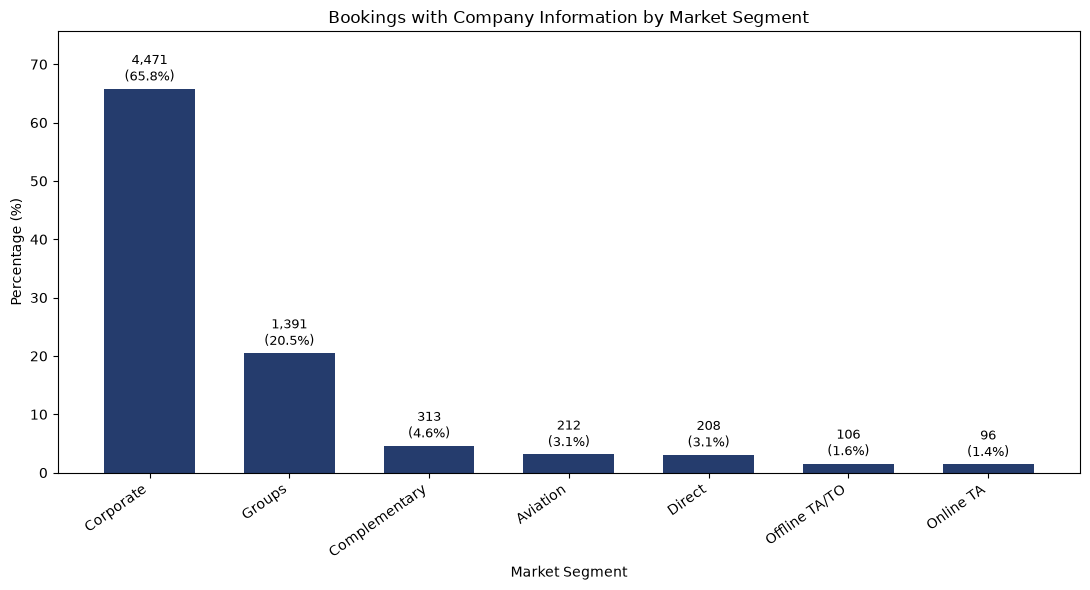

In [15]:
plt.figure(figsize=(11, 6))

bars = plt.bar(
    segmeny_perc.index,
    segmeny_perc["Percentage"],
    color="#253C6D",
    width=0.65
)

plt.title("Bookings with Company Information by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=35, ha="right")

labels = [
    f"{count:,}\n({pct:.1f}%)"
    for count, pct in zip(
        segmeny_perc["Count"],
        segmeny_perc["Percentage"]
    )
]

plt.bar_label(bars, labels=labels, padding=3, fontsize=9)

plt.ylim(0, segmeny_perc["Percentage"].max() * 1.15)

plt.tight_layout()

plt.savefig(
    "../src/graphs/company_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
# Her market segmentindeki rezervasyonların yüzde kaçında company bilgisi bulunuyor?

segment_total = df["market_segment"].value_counts() # her segmentteki toplam kayıt sayısı
company_availability_pct = (Count / segment_total * 100).fillna(0).round(2)

company_availability_pct

market_segment
Aviation         89.45
Complementary    42.13
Corporate        84.44
Direct            1.65
Groups            7.02
Offline TA/TO     0.44
Online TA         0.17
Undefined         0.00
Name: count, dtype: float64

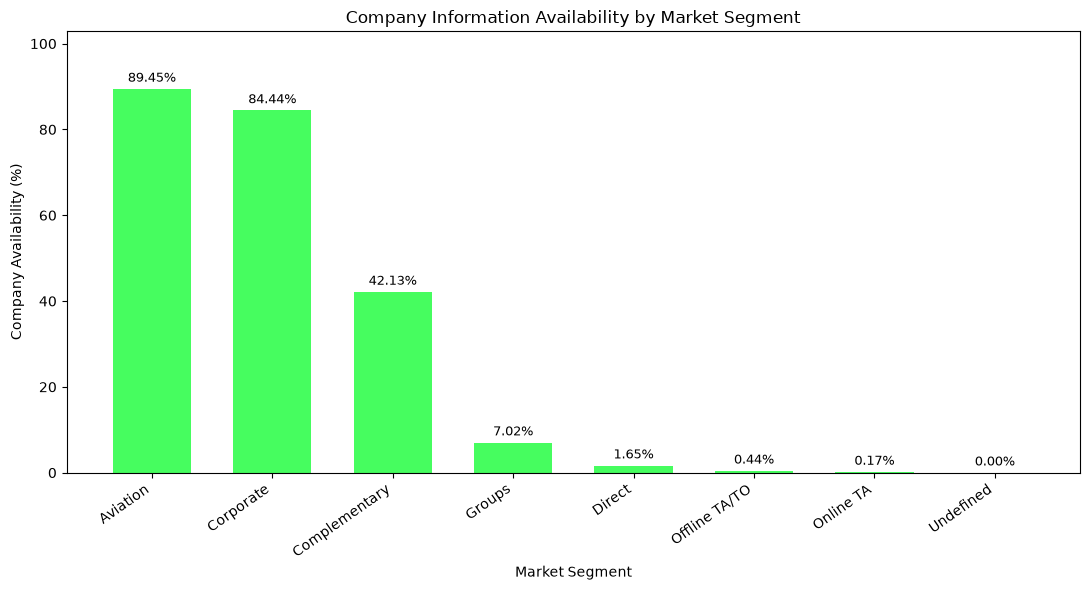

In [17]:
plt.figure(figsize=(11, 6))

company_availability_pct = company_availability_pct.sort_values(
    ascending=False
) 
bars = plt.bar(
    company_availability_pct.index,
    company_availability_pct.values,
    color="#46FD5F",
    width=0.65,
)

plt.title("Company Information Availability by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Company Availability (%)")
plt.xticks(rotation=35, ha="right")

labels = [
    f"{pct:.2f}%"
    for pct in company_availability_pct.values
]

plt.bar_label(bars, labels=labels, padding=3, fontsize=9)

plt.ylim(0, company_availability_pct.values.max() * 1.15)

plt.tight_layout()

plt.savefig(
    "../src/graphs/01-4Company Information Availability by Market Segment",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Company — Eksik Değer Analizi

**Analiz Bulguları**
- `company` kolonunda **112.593 eksik değer (%94,31)** bulunmaktadır.
- Company bilgisi bulunan 6.797 rezervasyonun **%65,78'i Corporate** segmentine aittir.
- Segment içi company doluluk oranı en yüksek **Aviation (%89,45)** ve **Corporate (%84,44)** segmentlerindedir.
- **Online TA (%0,17)** ve **Offline TA/TO (%0,44)** segmentlerinde company bilgisi neredeyse hiç bulunmamaktadır.

**Hipotezler**
- Company bilgisi, kurumsal rezervasyonlarda daha sık kullanılıyor olabilir.
- Bireysel veya aracı platformlar üzerinden yapılan rezervasyonlarda şirket bilgisi gerekli olmayabilir.
- Eksik değerler, sistemsel bir hatadan ziyade rezervasyon türüyle ilişkili olabilir.

**Sonuç ve Temizleme Kararı**

Company bilgisinin doluluk oranı market segmentlerine göre önemli farklılıklar göstermektedir. Bu durum, eksik değerlerin tamamen rastgele oluşmadığını düşündürmektedir; ancak nedenlerini kesin olarak kanıtlamamaktadır.

**Karar:** `company` kolonu şimdilik korunacak, eksik değerler doldurulmayacak veya silinmeyecektir. Kolonun sonraki analizlerde kullanılıp kullanılmayacağına göre nihai karar verilecektir.

In [18]:
df.head(5)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [19]:
df["distribution_channel"].value_counts()

distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64

In [20]:
# Agent bilgisi eksik olan rezervasyonlar hangi dağıtım kanallarında yoğunlaşıyor?
agent_missing_count = df[df["agent"].isna()]["distribution_channel"].value_counts()
agent_missing_count

distribution_channel
Direct       7625
Corporate    5543
TA/TO        3167
Undefined       3
GDS             2
Name: count, dtype: int64

In [21]:
# Her dağıtım kanalındaki rezervasyonların yüzde kaçında agent bilgisinin eksik?
channel_total = df["distribution_channel"].value_counts()
agent_missing_count = df[df["agent"].isna()]["distribution_channel"].value_counts()

agent_missing_rate_by_distribution_channel = (agent_missing_count / channel_total) * 100

agent_missing_rate_by_distribution_channel


distribution_channel
Corporate    83.016325
Direct       52.065551
GDS           1.036269
TA/TO         3.235925
Undefined    60.000000
Name: count, dtype: float64

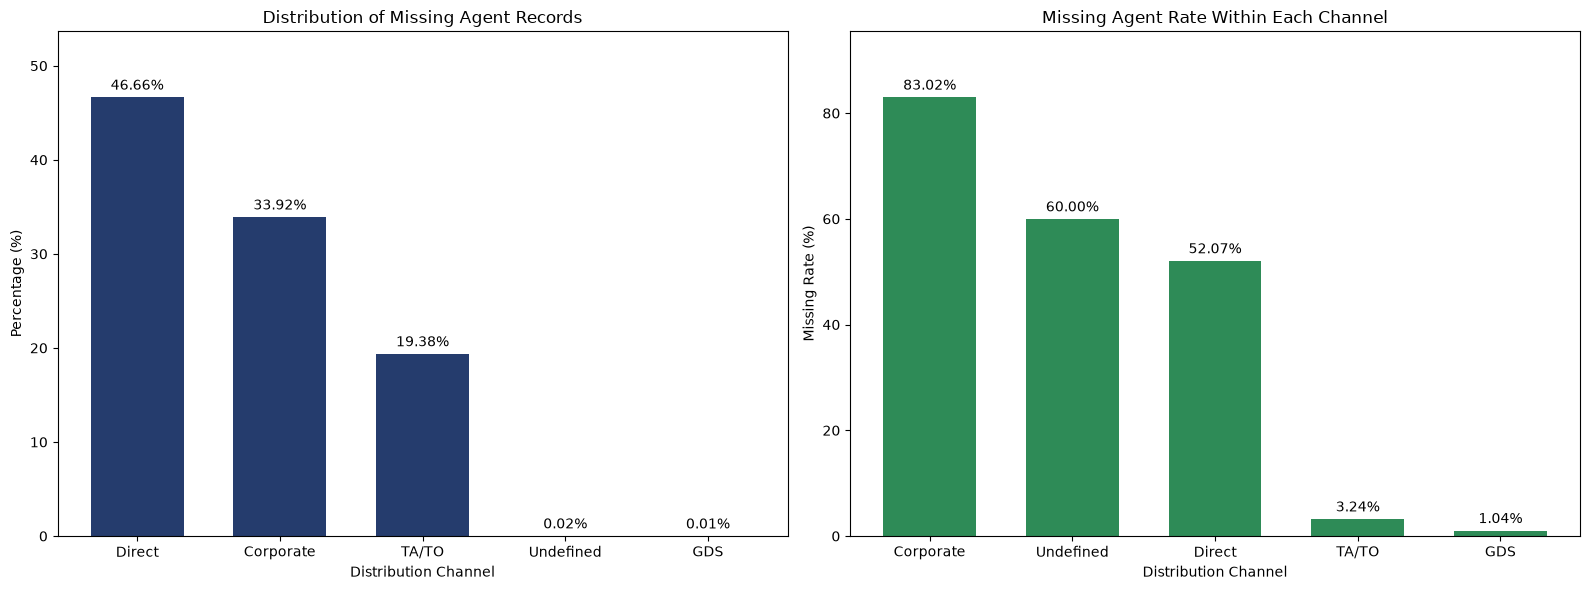

In [22]:
agent_distribution_pct = (
    agent_missing_count / agent_missing_count.sum() * 100
).round(2).sort_values(ascending=False)

agent_missing_rate = agent_missing_rate_by_distribution_channel.fillna(0).round(2).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bars1 = axes[0].bar(
    agent_distribution_pct.index,
    agent_distribution_pct.values,
    color="#253C6D",
    width=0.65
)

axes[0].set_title("Distribution of Missing Agent Records")
axes[0].set_xlabel("Distribution Channel")
axes[0].set_ylabel("Percentage (%)")

axes[0].bar_label(
    bars1,
    labels=[f"{v:.2f}%" for v in agent_distribution_pct.values],
    padding=3
)

axes[0].set_ylim(0, agent_distribution_pct.max() * 1.15)

bars2 = axes[1].bar(
    agent_missing_rate.index,
    agent_missing_rate.values,
    color="#2E8B57",
    width=0.65
)

axes[1].set_title("Missing Agent Rate Within Each Channel")
axes[1].set_xlabel("Distribution Channel")
axes[1].set_ylabel("Missing Rate (%)")

axes[1].bar_label(
    bars2,
    labels=[f"{v:.2f}%" for v in agent_missing_rate.values],
    padding=3
)

axes[1].set_ylim(0, max(agent_missing_rate.max() * 1.15, 1))

plt.tight_layout()
plt.show()

In [23]:
#agent kolonunda gerçekten 0 değerine sahip rezervasyon var mı?
len(df[df["agent"] == 0])

0

### Agent — Eksik Değer Analizi

**Analiz Bulguları**
- `agent` kolonunda **16.340 eksik değer (%13,69)** bulunmaktadır.
- Eksik kayıtların **%46,66'sı Direct**, **%33,92'si Corporate** ve **%19,38'i TA/TO** kanallarındadır.
- Kanal içi eksiklik oranı **Corporate (%83,02)**, **Direct (%52,07)** ve **TA/TO (%3,24)** olarak hesaplanmıştır.
- `agent` kolonunda `0` değerine sahip kayıt bulunmamaktadır.

**Hipotezler**
- Direct rezervasyonlarda aracı acente kullanılmamış olabilir.
- Corporate rezervasyonlar doğrudan şirket anlaşmaları üzerinden gerçekleştirilmiş olabilir.
- Eksik agent bilgilerinin dağıtım kanalıyla ilişkili olması, eksikliklerin her zaman veri giriş hatasından kaynaklanmadığını düşündürmektedir.

**Sonuç ve Temizleme Kararı**

Agent eksiklikleri dağıtım kanallarına göre farklılık göstermektedir. Ancak eksikliğin gerçek nedeni kesin olarak bilinmemektedir.

**Karar:** `agent` kolonu korunacak, eksik değerler şimdilik doldurulmayacak veya silinmeyecektir. Özellikle `NaN` değerlerinin `0` ile değiştirilmesi, doğrulanmamış bir anlam yükleyebileceği için tercih edilmemiştir.

In [24]:
#Country bilgisi eksik olan rezervasyonlar City Hotel ve Resort Hotel arasında nasıl dağılıyor?
df[df["country"].isna()]["hotel"].value_counts()

hotel
Resort Hotel    464
City Hotel       24
Name: count, dtype: int64

In [25]:
# Resort Hotel ve City Hotel rezervasyonlarının kendi içlerinde yüzde kaçında country bilgisi eksik?
country_missing_count = df[df["country"].isna()]["hotel"].value_counts()

hotel_total = df["hotel"].value_counts()

country_missing_rate = (
    country_missing_count / hotel_total * 100
).round(4)

country_missing_rate

hotel
City Hotel      0.0303
Resort Hotel    1.1583
Name: count, dtype: float64

In [26]:
# Country bilgisi eksik Resort Hotel rezervasyonları hangi dağıtım kanallarında yoğunlaşıyor?
df[df["country"].isna() & (df["hotel"] == "Resort Hotel")]["distribution_channel"].value_counts()

distribution_channel
Corporate    179
Direct       160
TA/TO        125
Name: count, dtype: int64

### Country — Eksik Değer Analizi

**Analiz Bulguları**
- `country` kolonunda **488 eksik değer (%0,41)** bulunmaktadır.
- Eksik kayıtların 464'ü Resort Hotel, 24'ü City Hotel rezervasyonlarına aittir.
- Otel içi eksiklik oranları Resort Hotel için **%1,1583**, City Hotel için **%0,0303** olarak hesaplanmıştır.
- Resort Hotel'deki eksiklikler Corporate (179), Direct (160) ve TA/TO (125) kanallarına dağılmaktadır.

**Hipotezler**
- Eksiklikler otellerin rezervasyon veya veri toplama süreçlerindeki farklılıklardan kaynaklanıyor olabilir.
- Eksikliklerin gerçek nedeni mevcut analizlerle kesinleştirilememiştir.

**Sonuç ve Temizleme Kararı**

Genel eksiklik oranı düşük olmasına rağmen kayıtların silinmesi Resort Hotel'i orantısız şekilde etkileyebilir.

**Karar:** Eksik `country` değerleri, rezervasyonları korumak amacıyla `Unknown` kategorisiyle doldurulacaktır. İşlem temizlenmiş veri seti oluşturulurken uygulanacaktır.

In [27]:
df[df["children"].isna()]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40600,City Hotel,1,2,2015,August,32,3,1,0,2,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
40667,City Hotel,1,1,2015,August,32,5,0,2,2,NaN,0,BB,PRT,Direct,Undefined,0,0,0,B,B,0,No Deposit,14.0,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
40679,City Hotel,1,1,2015,August,32,5,0,2,3,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,18.0,0,2,Canceled,2015-08-04
41160,City Hotel,1,8,2015,August,33,13,2,5,2,NaN,0,BB,PRT,Online TA,Undefined,0,0,0,B,B,0,No Deposit,9.0,NaN,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


In [28]:
df[df["distribution_channel"] == "Undefined"]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
14594,Resort Hotel,0,103,2015,July,28,5,2,3,2,1.0,0,HB,PRT,Direct,Undefined,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,112.7,1,2,Check-Out,2015-07-10
40600,City Hotel,1,2,2015,August,32,3,1,0,2,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
40667,City Hotel,1,1,2015,August,32,5,0,2,2,NaN,0,BB,PRT,Direct,Undefined,0,0,0,B,B,0,No Deposit,14.0,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
40679,City Hotel,1,1,2015,August,32,5,0,2,3,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,18.0,0,2,Canceled,2015-08-04
41160,City Hotel,1,8,2015,August,33,13,2,5,2,NaN,0,BB,PRT,Online TA,Undefined,0,0,0,B,B,0,No Deposit,9.0,NaN,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


In [29]:
#Undefined dağıtım kanalına sahip 5 rezervasyonun tamamı, 
#başka hangi alanlarda eksik veya alışılmadık değerlere sahip?
columns = [
    "hotel",
    "arrival_date_year",
    "arrival_date_month",
    "children",
    "agent",
    "company",
    "market_segment",
    "distribution_channel",
    "is_canceled"
]

df[df["distribution_channel"] == "Undefined"][columns]

,hotel,arrival_date_year,arrival_date_month,children,agent,company,market_segment,distribution_channel,is_canceled
14594,Resort Hotel,2015,July,1.0,NaN,NaN,Direct,Undefined,0
40600,City Hotel,2015,August,NaN,NaN,NaN,Undefined,Undefined,1
40667,City Hotel,2015,August,NaN,14.0,NaN,Direct,Undefined,1
40679,City Hotel,2015,August,NaN,NaN,NaN,Undefined,Undefined,1
41160,City Hotel,2015,August,NaN,9.0,NaN,Online TA,Undefined,1


### Children — Eksik Değer Analizi

**Analiz Bulguları**
- `children` kolonunda **4 eksik değer (%0,0034)** bulunmaktadır.
- Dört rezervasyonun tamamı City Hotel'e ve Ağustos 2015 varış dönemine aittir.
- Kayıtların tamamı iptal edilmiş ve `distribution_channel` bilgisi `Undefined` olarak kaydedilmiştir.
- `Undefined` dağıtım kanalındaki 5 rezervasyonun 4'ünde children bilgisi eksiktir.

**Hipotezler**
- Eksiklikler belirli bir dönemdeki veri giriş veya kayıt süreçleriyle ilişkili olabilir.
- Ancak kayıtların hatalı veya geçersiz olduğunu doğrulayacak yeterli kanıt bulunmamaktadır.

**Sonuç ve Temizleme Kararı**

Eksik kayıt sayısı oldukça düşük olmasına rağmen `0` ile doldurmak çocuk bulunmadığı varsayımını gerektirir.

**Karar:** Eksik değerler şimdilik korunacaktır. Çocuk sayısı gerektiren analizlerde bu kayıtlar ayrıca değerlendirilecektir.

Data Type & Consistency Checks

In [30]:
df["reservation_status_date"].dtype

<StringDtype(storage='python', na_value=nan)>

In [ ]:
# içinde "date" kelimesi geçen bütün kolonlar
df.filter(like="date").head(10) 

,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,reservation_status_date
0,2015,July,27,1,2015-07-01
1,2015,July,27,1,2015-07-01
2,2015,July,27,1,2015-07-02
3,2015,July,27,1,2015-07-02
4,2015,July,27,1,2015-07-03
5,2015,July,27,1,2015-07-03
6,2015,July,27,1,2015-07-03
7,2015,July,27,1,2015-07-03
8,2015,July,27,1,2015-05-06
9,2015,July,27,1,2015-04-22


In [ ]:
# tarih kolonunun tipini date yapalım
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])
df["reservation_status_date"].dtype

dtype('<M8[us]')

In [45]:
df.filter(regex="time|date").head(10)

,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,reservation_status_date
0,342,2015,July,27,1,2015-07-01
1,737,2015,July,27,1,2015-07-01
2,7,2015,July,27,1,2015-07-02
3,13,2015,July,27,1,2015-07-02
4,14,2015,July,27,1,2015-07-03
5,14,2015,July,27,1,2015-07-03
6,0,2015,July,27,1,2015-07-03
7,9,2015,July,27,1,2015-07-03
8,85,2015,July,27,1,2015-05-06
9,75,2015,July,27,1,2015-04-22


In [ ]:
df[["children","babies","adults","agent","company"]].dtypes # veri tipleri

children    float64
babies        int64
adults        int64
agent       float64
company     float64
dtype: object

In [ ]:
df[df["children"]%1!=0] # sadece boş değerler var

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40600,City Hotel,1,2,2015,August,32,3,1,0,2,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
40667,City Hotel,1,1,2015,August,32,5,0,2,2,NaN,0,BB,PRT,Direct,Undefined,0,0,0,B,B,0,No Deposit,14.0,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
40679,City Hotel,1,1,2015,August,32,5,0,2,3,NaN,0,BB,PRT,Undefined,Undefined,0,0,0,B,B,0,No Deposit,NaN,NaN,0,Transient-Party,18.0,0,2,Canceled,2015-08-04
41160,City Hotel,1,8,2015,August,33,13,2,5,2,NaN,0,BB,PRT,Online TA,Undefined,0,0,0,B,B,0,No Deposit,9.0,NaN,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


In [57]:
df["children"] = df["children"].astype("Int64") # children kolonunu tam sayıya çeviriyoruz
df["children"].dtype

Int64Dtype()

In [59]:
df[df["agent"]%1!=0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,NaN,NaN,0,Transient,107.00,0,0,Check-Out,2015-07-03
18,Resort Hotel,0,0,2015,July,27,1,0,1,2,0,0,BB,FRA,Corporate,Corporate,0,0,0,A,G,0,No Deposit,NaN,110.0,0,Transient,107.42,0,0,Check-Out,2015-07-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119124,City Hotel,0,0,2017,August,35,29,0,1,1,0,0,BB,PRT,Complementary,Corporate,0,0,0,A,A,0,No Deposit,NaN,72.0,0,Transient,0.00,0,2,Check-Out,2017-08-30
119151,City Hotel,0,0,2017,August,35,29,0,1,2,2,0,BB,NLD,Direct,Direct,0,0,0,G,G,0,No Deposit,NaN,NaN,0,Transient,270.00,0,0,Check-Out,2017-08-30
119166,City Hotel,0,0,2017,August,35,30,0,1,1,0,0,BB,BRA,Direct,Direct,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,140.00,0,0,Check-Out,2017-08-31
119215,City Hotel,0,2,2017,August,35,31,0,1,1,0,0,SC,LBN,Direct,Direct,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,140.00,0,2,Check-Out,2017-09-01


In [60]:
df[df["company"]%1!=0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [61]:
# önce kesirli değerleri var mı diye agent ve company kolonlarını kontrol ettik. 
# şimdi de kategorik değerler oldukları için str yapmamız daha mantıklı.
# kesirli kısımları atmak için önce int sonra str dönüşümü yapacağız.

df["agent"] = df["agent"].astype("Int64")
df["company"] = df["company"].astype("Int64")

df["agent"] = df["agent"].astype("string")
df["company"] = df["company"].astype("string")

df[["agent","company"]].dtypes

agent      string
company    string
dtype: object

In [62]:
df[["agent","company"]].isna().sum()

agent       16340
company    112593
dtype: int64

In [64]:
df[["children","babies","adults"]].describe()

,children,babies,adults
count,119386.0,119390.000000,119390.000000
mean,0.10389,0.007949,1.856403
std,0.398561,0.097436,0.579261
min,0.0,0.000000,0.000000
25%,0.0,0.000000,2.000000
50%,0.0,0.000000,2.000000
75%,0.0,0.000000,2.000000
max,10.0,10.000000,55.000000


In [71]:
df[(df["children"] == 0) & (df["babies"] == 0) & (df["adults"] == 0)]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,0,0,SC,PRT,Corporate,Corporate,0,0,0,A,I,1,No Deposit,<NA>,174,0,Transient-Party,0.00,0,0,Check-Out,2015-10-06
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,0,0,SC,PRT,Corporate,Corporate,0,0,0,A,I,0,No Deposit,<NA>,174,0,Transient,0.00,0,0,Check-Out,2015-10-12
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,0,0,SC,ESP,Groups,TA/TO,0,0,0,A,C,0,No Deposit,38,<NA>,0,Transient-Party,0.00,0,0,Check-Out,2015-11-23
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,0,0,SC,PRT,Groups,TA/TO,0,0,0,A,A,1,No Deposit,308,<NA>,122,Transient-Party,0.00,0,0,Check-Out,2016-01-04
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,0,0,SC,PRT,Groups,TA/TO,0,0,0,A,C,1,No Deposit,308,<NA>,122,Transient-Party,0.00,0,0,Check-Out,2016-01-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,26,27,0,3,0,0,0,BB,CHE,Online TA,TA/TO,0,0,0,A,A,1,No Deposit,7,<NA>,0,Transient,100.80,0,0,Check-Out,2017-06-30
115091,City Hotel,0,1,2017,June,26,30,0,1,0,0,0,SC,PRT,Complementary,Direct,0,0,0,E,K,0,No Deposit,<NA>,<NA>,0,Transient,0.00,1,1,Check-Out,2017-07-01
116251,City Hotel,0,44,2017,July,28,15,1,1,0,0,0,SC,SWE,Online TA,TA/TO,0,0,0,A,K,2,No Deposit,425,<NA>,0,Transient,73.80,0,0,Check-Out,2017-07-17
116534,City Hotel,0,2,2017,July,28,15,2,5,0,0,0,SC,RUS,Online TA,TA/TO,0,0,0,A,K,1,No Deposit,9,<NA>,0,Transient-Party,22.86,0,1,Check-Out,2017-07-22


In [73]:
# adults, children ve babies kolonlarının aynı anda 0 olduğu kayıtları inceleyelim

zero_guests = df[(df["children"] == 0) & (df["babies"] == 0) & (df["adults"] == 0)]

zero_guests["reservation_status"].value_counts()

reservation_status
Check-Out    155
Canceled      24
No-Show        1
Name: count, dtype: int64

Yetişkin, çocuk ve bebek sayılarının tamamı sıfır olan 180 kayıt (%0,15) tespit edilmiştir. Bunların 155’i Check-Out, 24’ü Canceled, 1’i No-Show durumundadır. Kayıtlar misafir sayısı açısından şüpheli olarak değerlendirilmiş; nedenleri doğrulanamadığından bu aşamada korunmuştur.

In [74]:
df["adults"].value_counts().sort_index(ascending=False)

adults
55        1
50        1
40        1
27        2
26        5
20        2
10        1
6         1
5         2
4        62
3      6202
2     89680
1     23027
0       403
Name: count, dtype: int64

403 kayıtta yetişkin sayısı sıfır; bunların 180’inde çocuk ve bebek de sıfırdı. kalan 223 kayıtta yetişkin sayısı sıfırken çocuk veya bebek sayısı pozitif görünüyor.

In [78]:
df[df["adults"]>=10][["adults","children","babies","market_segment","customer_type","reservation_status"]]

,adults,children,babies,market_segment,customer_type,reservation_status
1539,40,0,0,Direct,Group,Canceled
1587,26,0,0,Offline TA/TO,Group,Canceled
1643,50,0,0,Direct,Group,Canceled
1752,26,0,0,Offline TA/TO,Group,Canceled
1884,26,0,0,Offline TA/TO,Group,Canceled
1917,27,0,0,Direct,Group,Canceled
1962,27,0,0,Direct,Group,Canceled
2003,26,0,0,Offline TA/TO,Group,Canceled
2164,26,0,0,Offline TA/TO,Group,Canceled
2173,55,0,0,Direct,Group,Canceled


In [76]:
df["customer_type"].value_counts()

customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64

Yetişkin sayısı 10 ve üzeri olan 13 kayıt incelenmiştir. Kayıtların tamamı Group müşteri tipinde ve Canceled durumundadır. Grup rezervasyonlarıyla ilişkili olabilecek bu yüksek değerler, hatalı oldukları doğrulanamadığından korunmuştur.

In [79]:
df[["children","babies"]].value_counts().sort_index(ascending=False)

children  babies
10        0              1
3         0             76
2         1             32
          0           3620
1         2              3
          1            140
          0           4718
0         10             1
          9              1
          2             12
          1            728
          0         110054
Name: count, dtype: int64

In [80]:
df[(df["children"] >= 10) | (df["babies"] >= 9)][["adults","children","babies","market_segment","customer_type","reservation_status"]]


,adults,children,babies,market_segment,customer_type,reservation_status
328,2,10,0,Offline TA/TO,Contract,No-Show
46619,2,0,10,Online TA,Transient,Check-Out
78656,1,0,9,Corporate,Transient-Party,Check-Out


Bir rezervasyonda 10 çocuk, iki rezervasyonda ise sırasıyla 9 ve 10 bebek kaydedildiği görülmüştür. Bu uç değerlerin doğruluğu mevcut bilgilerle teyit edilemediğinden kayıtlar korunmuştur. EDA aşamasında ilgili analizlere etkileri değerlendirilecektir.